# Tokyo Electricity Demand Analysis (Python · pandas · NumPy)

**Question:** what drives electricity demand in the Tokyo area: temperature, time of day, the calendar, or solar power?

**Data:** `tokyo_hourly_clean.csv.gz`, 39,744 hourly records from 1 Apr 2022 to 12 Oct 2026 (JST), cleaned in an earlier project.
* **TEPCO Power Grid "でんき予報":** demand, TEPCO's day-ahead forecast, supply capacity, usage rate and solar output (GW).
* **Japan Meteorological Agency:** hourly temperature, humidity and sunshine at the Tokyo station, plus a Kanto-wide average.

**Contents**
1. Basic statistics
2. Highest and lowest values
3. Group and compare
4. Trends
5. Relationships between columns
6. Key findings

All functions live in `analysis.py`; this notebook calls them and shows the results.

In [1]:
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
import analysis as A

r = A.run(save=True)      # runs every analysis, saves the CSV tables and PNG charts
df = r["df"]
print(f"{len(df):,} hourly rows, {df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d}")
df.head()

39,744 hourly rows, 2022-04-01 to 2026-10-12


,year,month,hour,weekday,season,is_holiday,is_workday,demand_gw,tepco_forecast_gw,supply_gw,usage_rate_pct,solar_gw,temp_tokyo_c,rh_tokyo_pct,sun_tokyo_h,temp_kanto_c,sun_kanto_h,day_type,net_demand_gw,forecast_error_gw,abs_pct_error,temp_band
datetime,,,,,,,,,,,,,,,,,,,,,,
2022-04-01 00:00:00,2022,4,0,Friday,Spring,False,True,25.29,24.88,31.14,81,0.0,8.60,95.0,0.0,8.736,0.0,Workday,25.29,0.41,1.621194,8 to 10
2022-04-01 01:00:00,2022,4,1,Friday,Spring,False,True,24.43,24.35,30.88,79,0.0,7.80,95.0,0.0,7.968,0.0,Workday,24.43,0.08,0.327466,6 to 8
2022-04-01 02:00:00,2022,4,2,Friday,Spring,False,True,24.55,24.35,30.88,79,0.0,6.95,95.0,0.0,7.068,0.0,Workday,24.55,0.20,0.814664,6 to 8
2022-04-01 03:00:00,2022,4,3,Friday,Spring,False,True,25.07,24.67,31.21,80,0.0,6.10,95.5,0.0,6.170,0.0,Workday,25.07,0.40,1.595533,6 to 8
2022-04-01 04:00:00,2022,4,4,Friday,Spring,False,True,25.69,25.28,31.24,82,0.0,5.40,95.0,0.0,5.398,0.0,Workday,25.69,0.41,1.595952,4 to 6


## 1. Basic statistics
Count, mean, spread, percentiles and shape (skew, kurtosis) for every main column.

In [2]:
r["basic_statistics"]

,count,mean,std,min,5%,25%,50%,75%,95%,max,iqr,cv_pct,skew,kurtosis,missing
demand_gw,39744.0,31.71,7.07,18.53,22.25,26.35,30.71,35.89,45.07,59.30,9.54,22.30,0.76,0.24,0
tepco_forecast_gw,39744.0,31.72,7.09,18.34,22.22,26.34,30.72,35.93,45.08,59.29,9.59,22.35,0.75,0.23,0
supply_gw,39744.0,38.56,8.20,21.14,26.04,32.53,37.72,44.46,52.81,67.42,11.93,21.27,0.34,-0.48,0
usage_rate_pct,39744.0,81.91,6.19,57.00,70.00,78.00,83.00,87.00,90.00,99.00,9.00,7.56,-0.66,0.18,0
solar_gw,39744.0,2.86,4.26,0.00,0.00,0.00,0.07,4.88,12.31,17.76,4.88,148.97,1.36,0.53,0
temp_tokyo_c,39744.0,17.96,8.44,-3.15,4.30,11.05,18.40,24.95,30.90,38.05,13.90,46.96,-0.09,-0.98,0
rh_tokyo_pct,39744.0,69.63,19.41,16.50,35.50,55.50,71.00,85.00,98.50,100.00,29.50,27.87,-0.29,-0.77,0
sun_tokyo_h,39744.0,0.24,0.39,0.00,0.00,0.00,0.00,0.40,1.00,1.00,0.40,164.20,1.23,-0.30,0


**Reading the table**
* Demand averages **31.7 GW** (SD 7.1) and ranges from **18.5 to 59.3 GW**, a 3.2x swing.
* Demand is **right-skewed** (skew 0.76): most hours are moderate, and a few very hot hours pull the tail up.
* Solar output is 0 for about half of all hours (the median is 0.07 GW) because there is no sun at night. That makes it the most skewed column (1.36).

In [3]:
# NumPy view: share of hours in demand ranges
bins = np.array([15, 25, 30, 35, 40, 45, 50, 60])
counts, _ = np.histogram(df["demand_gw"], bins=bins)
pd.DataFrame({"demand_range_gw": [f"{a}-{b}" for a, b in zip(bins[:-1], bins[1:])],
              "hours": counts, "share_pct": np.round(counts / counts.sum() * 100, 1)})

,demand_range_gw,hours,share_pct
0,15-25,7153,18.0
1,25-30,11034,27.8
2,30-35,10407,26.2
3,35-40,5788,14.6
4,40-45,3347,8.4
5,45-50,1309,3.3
6,50-60,706,1.8


## 2. Highest and lowest values

In [4]:
ext = r["extremes"]
ext[ext["measure"] == "Demand"]

,measure,kind,rank,datetime,value,demand_gw,temp_tokyo_c,day_type,holiday
0,Demand,highest,1,2022-08-02 13:00,59.30,59.30,34.9,Workday,False
1,Demand,highest,2,2022-08-02 14:00,59.21,59.21,35.2,Workday,False
2,Demand,highest,3,2022-08-03 13:00,58.89,58.89,34.5,Workday,False
3,Demand,highest,4,2022-08-02 15:00,58.50,58.50,34.8,Workday,False
4,Demand,highest,5,2022-08-03 14:00,58.48,58.48,32.9,Workday,False
5,Demand,lowest,1,2025-05-04 06:00,18.53,18.53,15.9,Weekend/holiday,True
6,Demand,lowest,2,2024-05-05 06:00,18.55,18.55,18.6,Weekend/holiday,True
7,Demand,lowest,3,2025-05-05 01:00,18.61,18.61,14.1,Weekend/holiday,True
8,Demand,lowest,4,2025-05-05 06:00,18.63,18.63,14.9,Weekend/holiday,True
9,Demand,lowest,5,2024-05-04 06:00,18.64,18.64,16.8,Weekend/holiday,True


In [5]:
ext[ext["measure"] != "Demand"]

,measure,kind,rank,datetime,value,demand_gw,temp_tokyo_c,day_type,holiday
10,Tokyo temperature,highest,1,2025-08-30 12:00,38.05,46.67,38.0,Weekend/holiday,False
11,Tokyo temperature,highest,2,2025-08-30 13:00,37.50,47.27,37.5,Weekend/holiday,False
12,Tokyo temperature,highest,3,2023-07-12 13:00,37.05,53.82,37.0,Workday,False
13,Tokyo temperature,highest,4,2023-07-18 12:00,36.95,53.79,37.0,Workday,False
14,Tokyo temperature,highest,5,2023-07-18 13:00,36.95,55.15,37.0,Workday,False
15,Tokyo temperature,lowest,1,2023-01-26 06:00,-3.15,42.70,-3.1,Workday,False
16,Tokyo temperature,lowest,2,2023-01-25 06:00,-2.65,42.07,-2.6,Workday,False
17,Tokyo temperature,lowest,3,2023-01-25 07:00,-2.45,46.49,-2.5,Workday,False
18,Tokyo temperature,lowest,4,2023-01-26 05:00,-2.45,37.04,-2.5,Workday,False
19,Tokyo temperature,lowest,5,2023-01-25 05:00,-2.35,36.60,-2.4,Workday,False


In [6]:
r["yearly_records"]

,hours,max_demand_gw,max_demand_at,min_demand_gw,max_temp_c,hours_35c_plus,max_solar_gw,hours_usage_95pct_plus
year,,,,,,,,
2022,6600,59.30,2022-08-02 13:00,19.53,35.85,17,15.16,29
2023,8760,55.25,2023-07-18 14:00,18.88,37.05,32,16.01,2
2024,8784,56.99,2024-07-29 14:00,18.55,36.90,20,16.63,28
2025,8760,57.54,2025-08-06 13:00,18.53,38.05,50,16.52,11
2026,6840,56.42,2026-07-22 14:00,18.65,36.75,17,17.76,27


* The **five highest demand hours** were all on 2–3 Aug 2022, at 13:00–15:00 in about 33–35 °C heat. The record is **59.3 GW**.
* The **five lowest hours** all fall in **Golden Week** (4–5 May), between 01:00 and 06:00, with mild weather and businesses closed.
* The tightest hour was **99 % usage** (demand ÷ supply) at 17:00 on 22 Jul 2026.

## 3. Group and compare

In [7]:
r["by_season_hour"].T.round(1)

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
season,,,,,,,,,,,,,,,,,,,,,,,,
Winter,29.6,28.4,28.1,28.0,28.4,29.9,33.2,36.2,38.4,38.9,37.9,37.0,35.5,35.6,35.4,35.6,37.0,38.6,39.1,38.6,37.7,36.2,34.1,32.0
Spring,24.0,23.0,22.9,23.2,23.4,23.8,24.8,26.4,28.8,30.7,31.2,31.4,30.5,30.8,30.6,30.4,30.6,30.9,31.6,31.2,30.1,28.6,27.2,25.7
Summer,27.8,26.0,25.3,25.2,25.2,25.5,27.0,30.3,35.0,38.8,40.4,41.5,41.3,42.1,42.0,41.6,41.1,39.8,39.0,37.9,36.1,34.0,32.2,30.3
Autumn,25.0,23.7,23.4,23.6,23.9,24.5,25.7,27.9,31.0,33.3,34.2,34.6,34.0,34.7,34.7,34.5,34.6,34.6,34.2,33.0,31.6,30.0,28.5,27.0


In [8]:
r["peak_hour_by_season"]

,most_common_peak_hours,share_of_days_pct
season,,
Winter,"[9, 18]",65.9
Spring,"[18, 11]",53.8
Summer,"[14, 13]",58.7
Autumn,"[17, 18]",43.1


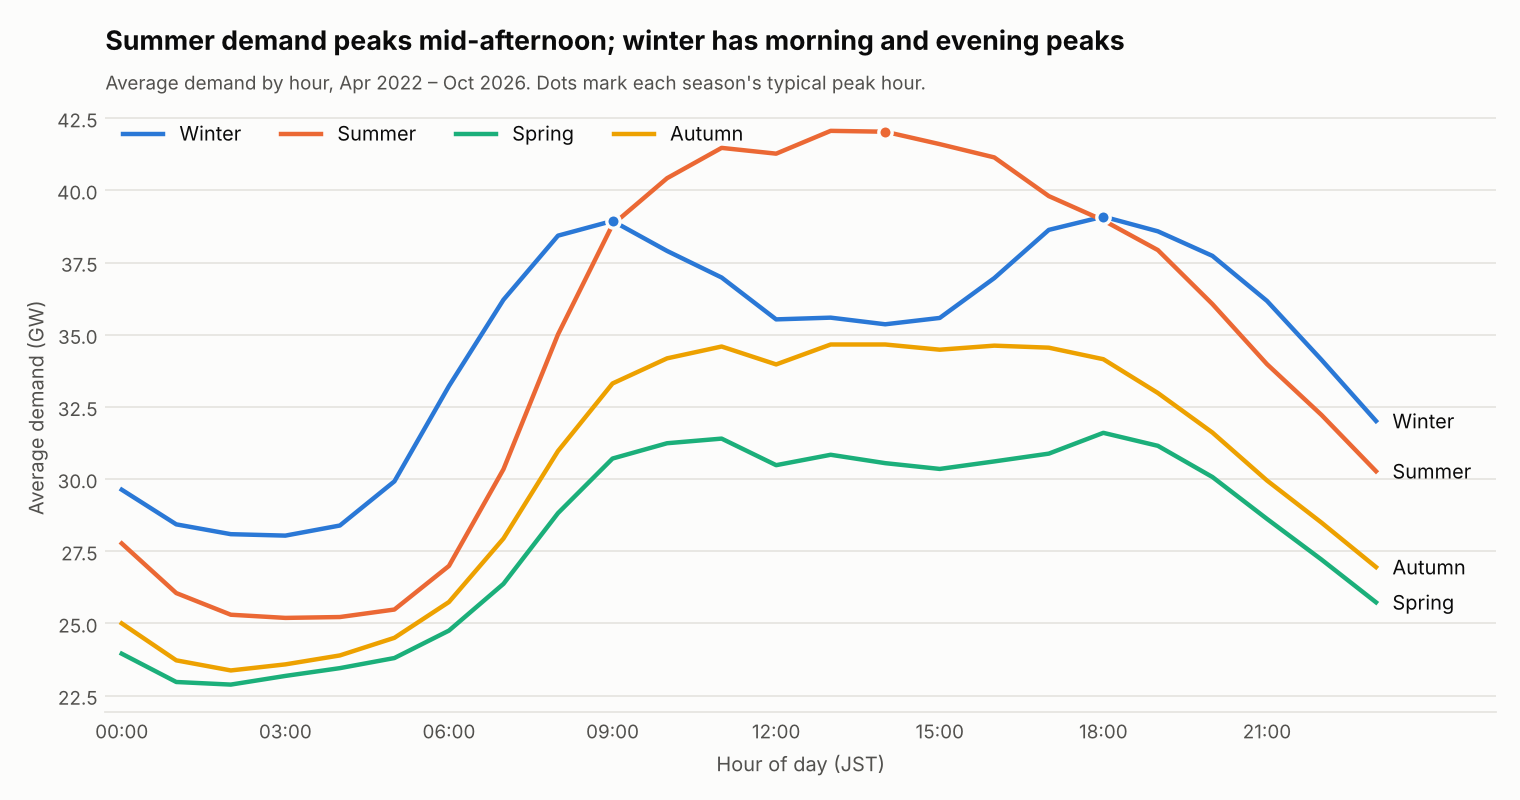

In [9]:
display(Image("fig1_daily_profile_by_season.png", width=800))

In [10]:
print(r["day_type"])
print("\nWorkday minus weekend/holiday demand, by hour (GW):")
print(r["workday_gap_by_hour"].round(1).to_frame("gap_gw").T.to_string())
r["by_weekday"]

                 count   mean  median    max    min
day_type                                           
Weekend/holiday  13680  29.05   27.98  47.72  18.53
Workday          26064  33.11   32.14  59.30  19.49

Workday minus weekend/holiday demand, by hour (GW):
hour     0    1    2    3    4    5    6    7    8    9    10   11   12   13   14   15   16   17   18   19   20   21   22   23
gap_gw  0.7  0.7  0.8  0.9  1.1  1.9  3.4  4.8  6.3  7.1  7.0  6.8  5.8  6.8  7.0  6.7  6.4  5.0  4.2  3.5  3.1  2.7  2.5  2.2


,mean,max,min
weekday,,,
Monday,32.20,57.44,18.61
Tuesday,33.14,59.30,18.67
Wednesday,33.15,58.89,19.07
Thursday,32.92,56.28,18.88
Friday,32.66,55.46,18.88
Saturday,29.52,47.72,18.64
Sunday,28.42,47.50,18.53


In [11]:
r["by_month"]

,mean_demand_gw,max_demand_gw,mean_supply_gw,mean_temp_c,mean_solar_gw,hours_usage_95pct_plus
month,,,,,,
1,35.33,51.37,42.91,6.38,2.52,2
2,35.03,51.79,42.59,7.44,2.87,3
3,30.82,48.37,37.77,11.07,3.05,6
4,27.27,43.39,33.48,16.16,3.18,2
5,26.41,38.21,32.57,19.45,3.27,15
6,29.87,54.87,36.56,23.09,3.11,12
7,36.62,56.99,43.88,28.07,3.38,14
8,36.54,59.30,43.92,28.41,3.21,20
9,33.02,55.21,39.94,25.36,2.55,20


* **Summer** demand peaks at **13:00–14:00**, when air conditioning is running hardest. **Winter** has two peaks, at **09:00 and 18:00**, from morning and evening heating and lighting.
* **Workdays average 33.1 GW**, compared with 29.0 GW on weekends and holidays (+4.1 GW). The gap is largest during office hours, up to 7.1 GW at 09:00. Sunday is the lowest day at 28.4 GW.
* **July and August** are the highest-demand months (about 36.6 GW), with **January and February** next (about 35 GW). **May** is the lowest (26.4 GW).

## 4. Trends

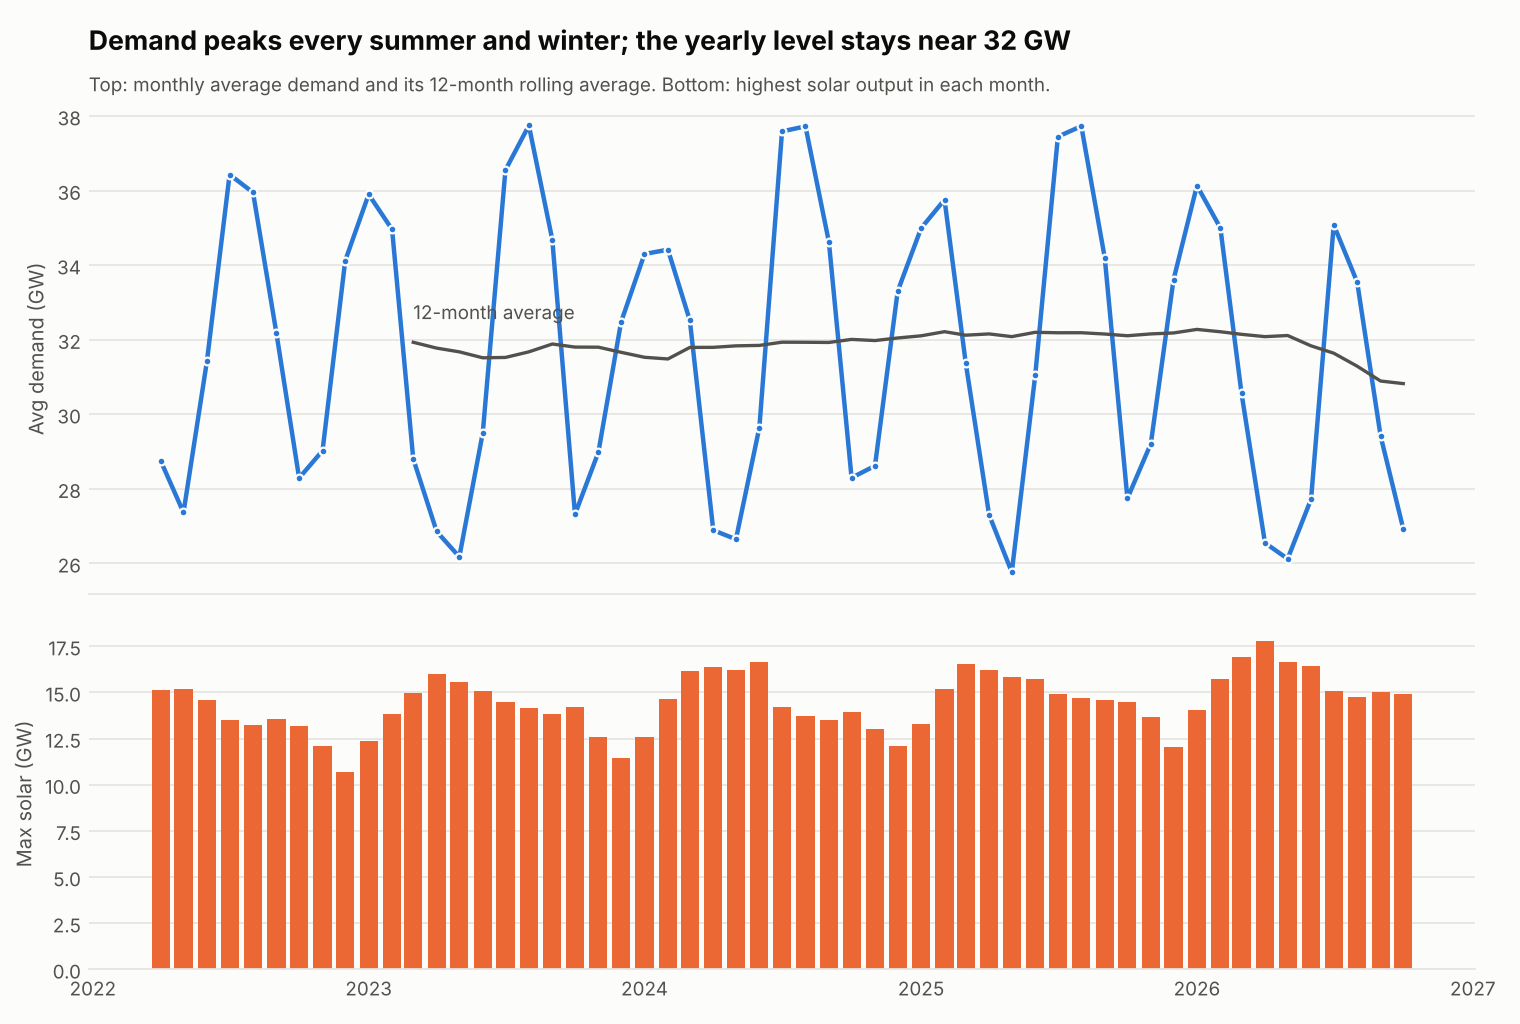

,mean_temp_c,hours_35c_plus,mean_demand_gw,peak_demand_gw
year,,,,
2022,27.46,11,36.19,59.30
2023,28.96,32,37.15,55.25
2024,28.86,20,37.66,56.99
2025,29.03,45,37.59,57.54
2026,26.91,17,34.31,56.42


In [12]:
display(Image("fig3_monthly_trends.png", width=800))
r["summer_by_year"]

In [13]:
print("Highest solar output each year:")
print(r["solar_trend"])
print(f"\nTrend in the 99th-percentile solar output: +{r['solar_p99_slope_gw_per_year']} GW per year (np.polyfit)")

Highest solar output each year:
      max_solar_gw  p99_solar_gw
year                            
2022         15.16         13.52
2023         16.01         14.14
2024         16.63         14.79
2025         16.52         14.79
2026         17.76         15.22

Trend in the 99th-percentile solar output: +0.405 GW per year (np.polyfit)


* **No long-run growth in demand:** the 12-month average stays close to 32 GW, and only the seasonal cycle repeats.
* **Hotter summers raise demand:** July–August hours at 35 °C or above went from 11 in 2022 to 45 in 2025, and the average summer demand rose from 36.2 to 37.6 GW. The cooler summer of 2026 (26.9 °C average) brought it down to 34.3 GW.
* **Solar keeps growing:** the highest solar hour rose from 15.2 GW (2022) to 17.8 GW (2026), and the 99th percentile climbs by about 0.4 GW per year.

## 5. Relationships between columns

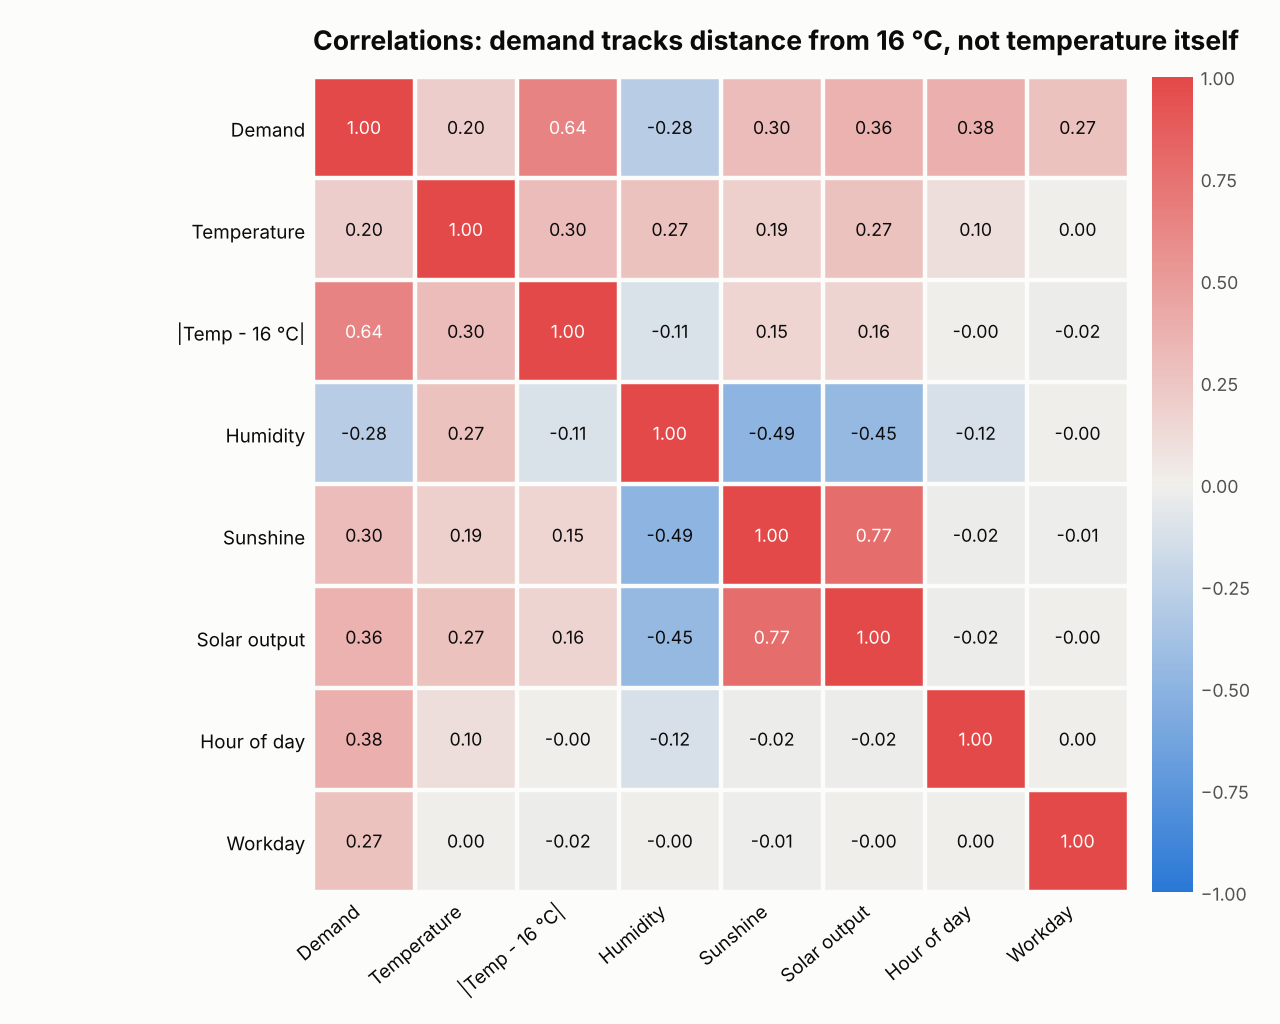

Correlation of demand with temperature itself: r = 0.20
Correlation of demand with |temperature - x|, strongest at x = 16.5 °C: r = 0.65


In [14]:
display(Image("fig5_correlation_matrix.png", width=640))
scan = r["comfort_scan"]
print(f"Correlation of demand with temperature itself: r = {df['demand_gw'].corr(df['temp_tokyo_c']):.2f}")
print(f"Correlation of demand with |temperature - x|, strongest at x = {scan.idxmax()} °C: r = {scan.max():.2f}")

Demand's correlation with temperature itself is weak (r = 0.20), because the relationship is **U-shaped**: both cold and heat push demand up. Measuring the **distance from about 16 °C** captures this, and the correlation rises to r = 0.64.

{'heating_gw_per_c': np.float64(1.09), 'heating_r2': np.float64(0.78), 'heating_n': 2855, 'cooling_gw_per_c': np.float64(1.81), 'cooling_r2': np.float64(0.86), 'cooling_n': 3931, 'cooling_vs_heating': np.float64(1.66)}


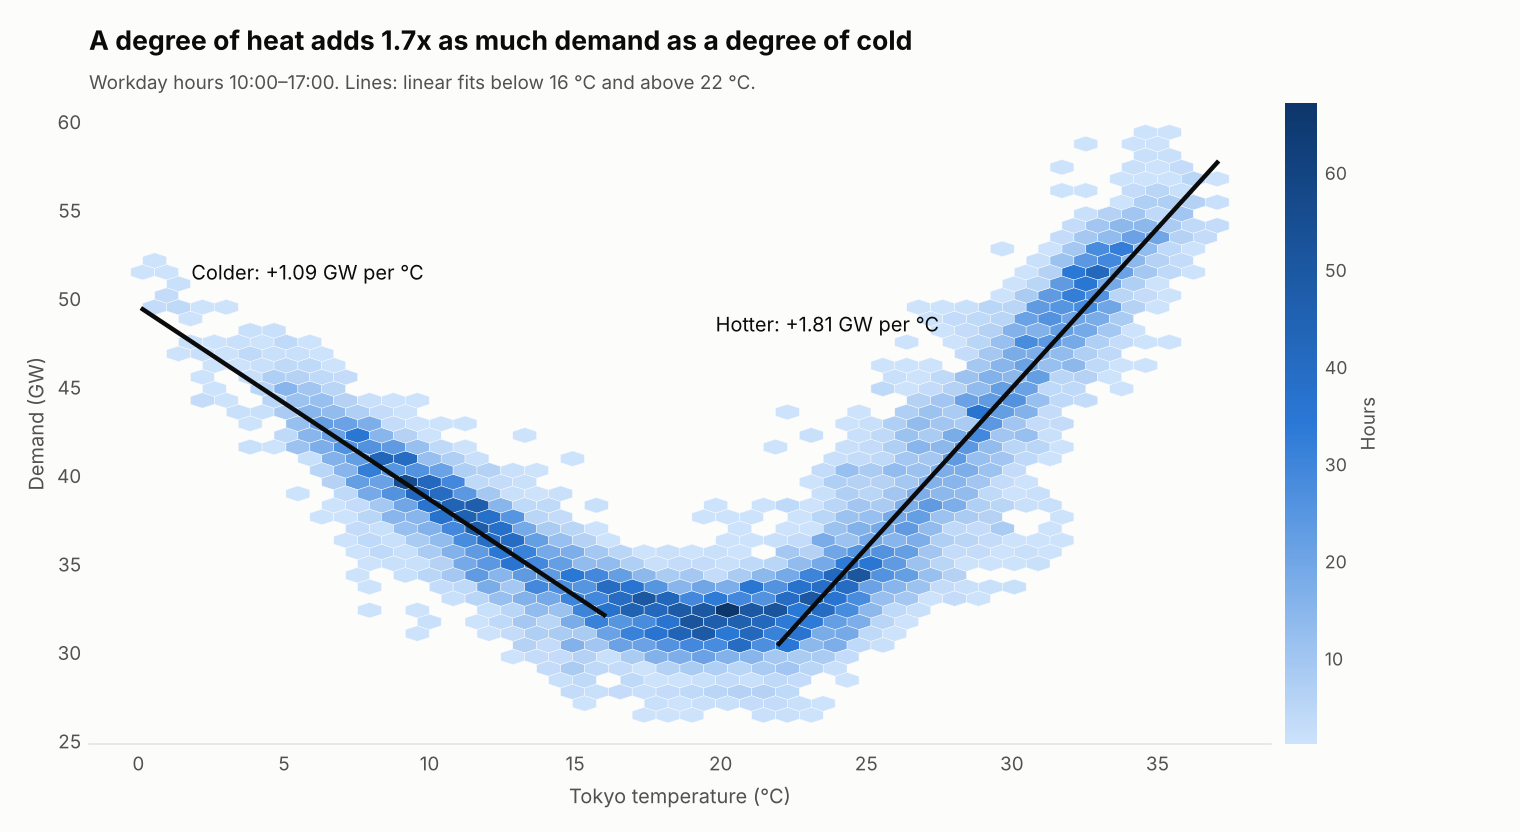

In [15]:
s = {k: v for k, v in r["slopes"].items() if not k.endswith("_fit")}
print(s)
display(Image("fig2_demand_vs_temperature.png", width=800))

In [16]:
print("Humidity on hot workday afternoons (28-34 °C, 12:00-16:00), multiple regression with np.linalg.lstsq:")
r["humidity"]

Humidity on hot workday afternoons (28-34 °C, 12:00-16:00), multiple regression with np.linalg.lstsq:


{'hours': 1110,
 'gw_per_c': np.float64(2.53),
 'gw_per_10pct_rh': np.float64(2.24),
 'r2': 0.77,
 'simple_r_rh': np.float64(0.12)}

Solar output vs Kanto sunshine at midday: r = 0.88
All-year average at noon: demand 35.4 GW, after solar 25.6 GW
Peak hour of total demand: 11 | peak hour of demand minus solar: 18


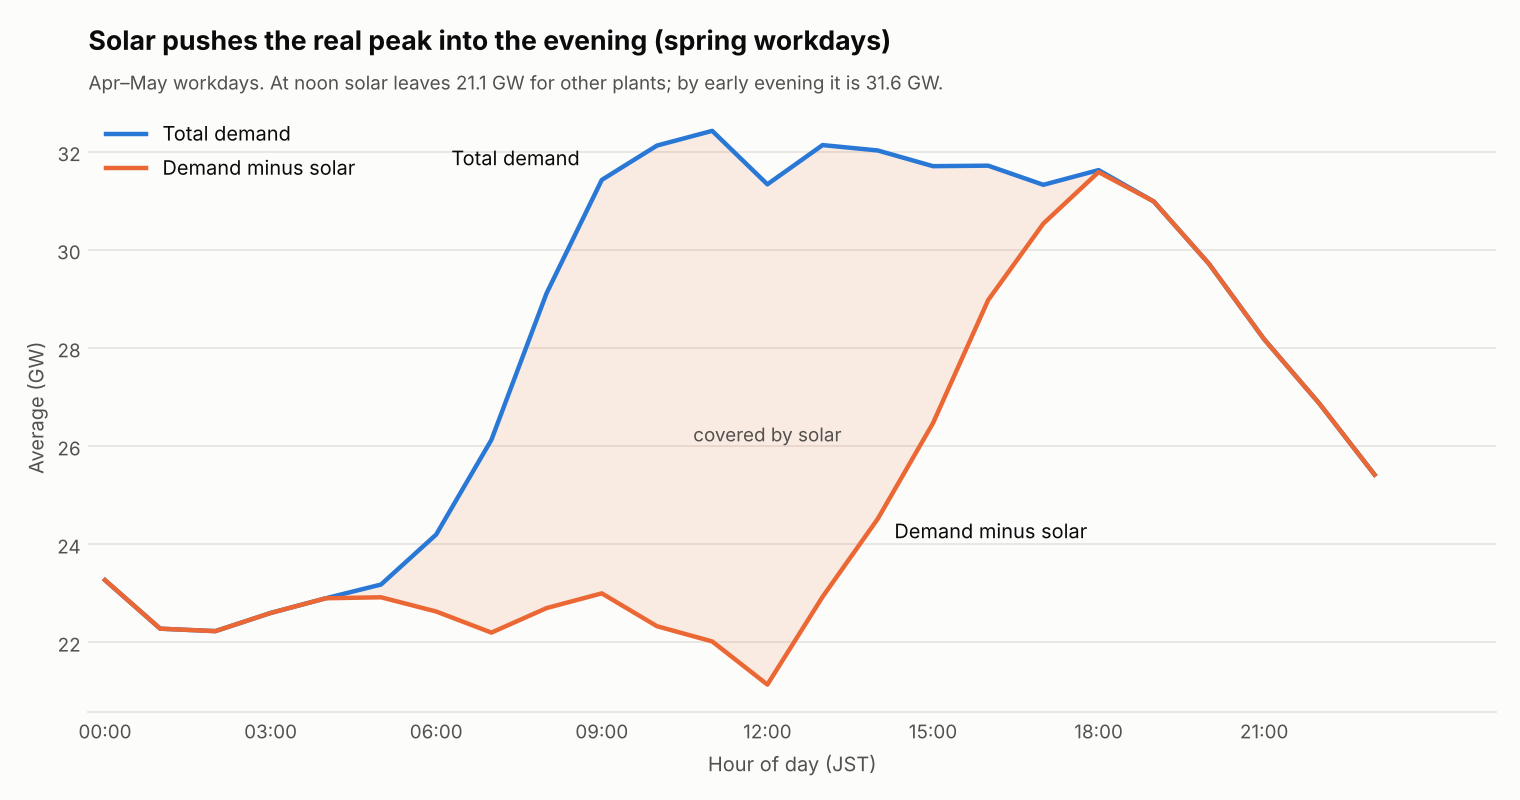

In [17]:
sol = r["solar"]
print("Solar output vs Kanto sunshine at midday: r =", sol["r_solar_vs_kanto_sunshine_midday"])
print("All-year average at noon: demand", sol["noon_demand_gw"], "GW, after solar", sol["noon_net_gw"], "GW")
print("Peak hour of total demand:", sol["demand_peak_hour"], "| peak hour of demand minus solar:", sol["net_peak_hour"])
display(Image("fig4_solar_net_demand.png", width=800))

TEPCO forecast: mean absolute % error 1.01 %, bias -0.012 GW
year
2022    0.95
2023    0.95
2024    1.00
2025    1.02
2026    1.12


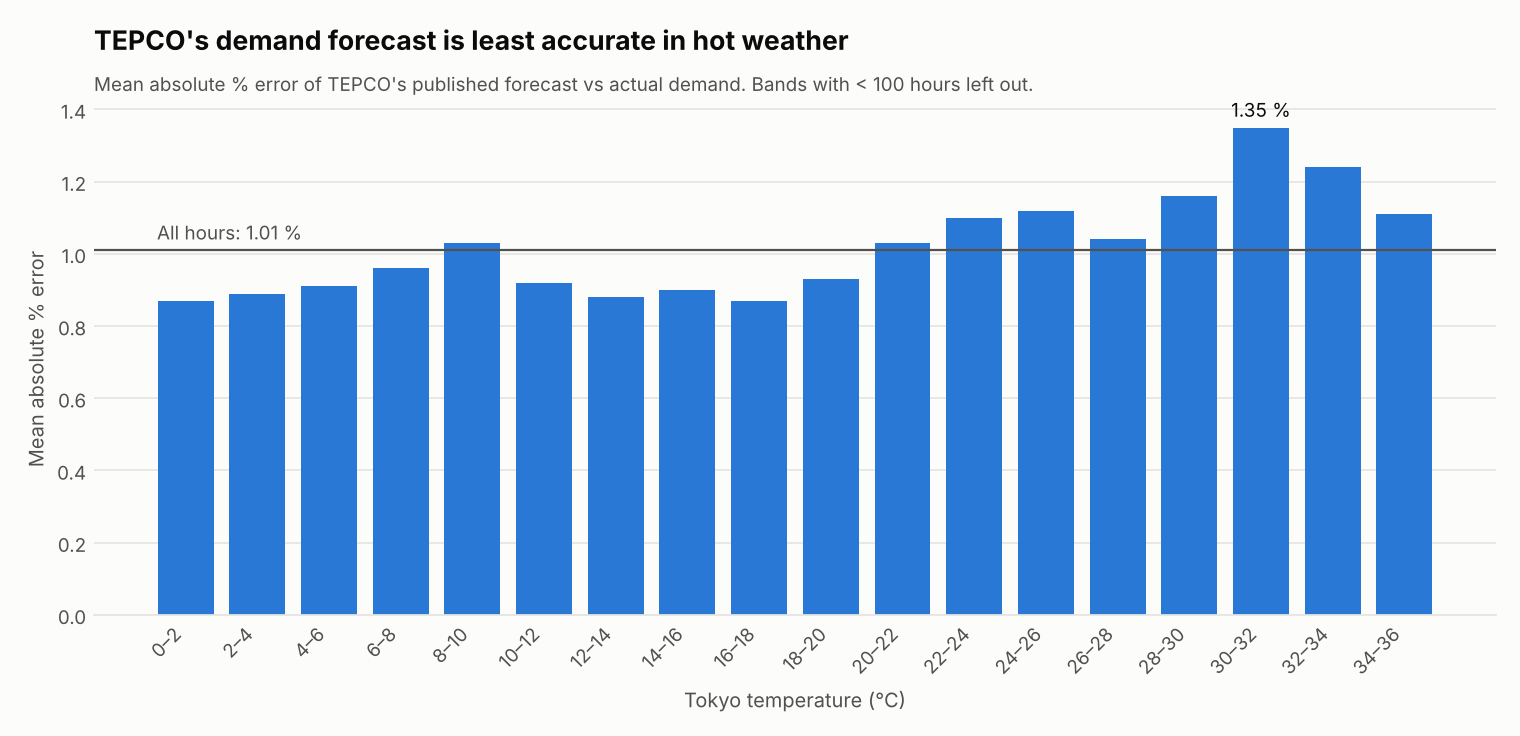

In [18]:
fc = r["forecast"]
print(f"TEPCO forecast: mean absolute % error {fc['mape_pct']} %, bias {fc['bias_gw']} GW")
print(fc["by_year"].to_string())
display(Image("fig6_forecast_error_by_temperature.png", width=800))

## 6. Key findings

1. **Heat costs more than cold.** On workday daytime hours, each °C above 22 °C adds **1.81 GW** of demand (R² 0.86), and each °C below 16 °C adds **1.09 GW** (R² 0.78). A degree of heat therefore adds about **1.7x as much demand** as a degree of cold, which is why the record peaks happen in summer.
2. **The relationship is U-shaped, so simple correlation misses it.** r = 0.20 with temperature, but r = 0.64 with the distance from about 16 °C, the temperature at which Tokyo needs neither heating nor cooling.
3. **Peak hours depend on the season.** Summer peaks at 13:00–14:00, while winter peaks at 09:00 and 18:00. Workdays run 4.1 GW above weekends and holidays on average, and the 5 lowest-demand hours in the whole dataset were all during Golden Week.
4. **Solar moves the real peak into the evening.** On spring workdays, solar cuts the demand left for other power plants from about 31 GW to **21.1 GW at noon**. That demand comes back to **31.6 GW by 18:00**, after sunset. The highest solar hour rose 17 % from 2022 to 2026.
5. **Humidity adds load on hot days.** At the same temperature (28–34 °C afternoons), every +10 % humidity adds about **2.2 GW**.
6. **Hotter summers mean higher demand, and harder forecasts.** Hours at 35 °C or above quadrupled from 2022 to 2025. TEPCO's forecast error is lowest in mild weather (0.87 %) and highest at 30–32 °C (1.35 %).